# EECE 5644 Project – HOG Shape Features
**Team:** Jingqi Mei & Andrew Chen

**Goal.** Shape errors (arrow vs. circle) are now the largest error source (~25%). This notebook adds
**HOG (Histogram of Oriented Gradients)** features and compares three feature sets under the same protocol:

| Feature set | Dims | Purpose |
|---|---|---|
| color + position + red | 41 | current best (reference) |
| HOG only | 756 | shape information alone |
| all | 797 | combined |

**Protocol** (unchanged): 18 training clips only, grouped CV by clip, pooled out-of-fold (OOF) metrics.
The 4 test sequences are not touched.

**New in this notebook**
- Resized patches are cached once (`cache/patches_*.npz`), so features can be recomputed in seconds without reading frames again.
- Fold assignment is computed once, stored in `ann["fold"]`, and can be exported for the teammate.
- Per-fold macro-F1 only averages over classes present in that fold.

Requires `scikit-image` (`python -m pip install scikit-image`).

In [2]:
import os, glob, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import cv2
from skimage.feature import hog
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (f1_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

In [3]:
# ---------------- Configuration ----------------
ROOT = "./data"
ANN  = os.path.join(ROOT, "Annotations", "Annotations")
CLASSES  = ["go", "goLeft", "stop", "stopLeft", "warning", "warningLeft"]
COLOR_OF = {"go": "green", "goLeft": "green", "stop": "red", "stopLeft": "red",
            "warning": "yellow", "warningLeft": "yellow"}

K_SUBSAMPLE = 5          # keep every k-th frame of each clip
MIN_H       = 5          # drop boxes shorter than this (pixels)
PATCH_WH    = (16, 32)   # resized patch size (width, height)
N_FOLDS     = 6
SEED        = 0

# HOG parameters (patch is tiny, so cells must be small to resolve the arrow)
HOG_ORIENT = 9           # number of orientation bins (Dalal & Triggs default)
HOG_PPC    = (4, 4)      # pixels per cell -> 4 x 8 cells on a 16 x 32 patch
HOG_CPB    = (2, 2)      # cells per block (block normalisation)

CACHE_DIR = "./cache"
os.makedirs(CACHE_DIR, exist_ok=True)

## 1. Load training annotations, filter, subsample

In [4]:
rows = []
for f in sorted(glob.glob(f"{ANN}/**/frameAnnotationsBOX.csv", recursive=True)):
    clip = os.path.relpath(os.path.dirname(f), ANN).replace(os.sep, "/")
    if "Train" not in clip:                      # keep the 4 test sequences untouched
        continue
    df = pd.read_csv(f, sep=";")
    df["clip"], df["isNight"] = clip, clip.lower().startswith("night")
    rows.append(df)
ann = pd.concat(rows, ignore_index=True).rename(columns={
    "Annotation tag": "tag", "Upper left corner X": "x1", "Upper left corner Y": "y1",
    "Lower right corner X": "x2", "Lower right corner Y": "y2"})
ann["frame"]    = ann["Filename"].map(os.path.basename)
ann["frame_no"] = ann["frame"].str.extract(r"--(\d+)\.jpg$", expand=False).astype(int)
ann["h"], ann["w"] = ann.y2 - ann.y1, ann.x2 - ann.x1
n0 = len(ann)

ann = ann[ann["tag"].isin(CLASSES)]                                   # drop e.g. goForward
ann = ann[(ann["w"] > 0) & (ann["h"] >= MIN_H)]                       # invalid / tiny boxes
ann = ann.drop_duplicates(["frame", "tag", "x1", "y1", "x2", "y2"])   # duplicate labels
ann = ann[ann["frame_no"] % K_SUBSAMPLE == 0].reset_index(drop=True)  # reduce redundancy
print(f"{n0} boxes -> {len(ann)} after filtering and subsampling (k={K_SUBSAMPLE})")
print(ann.groupby(["isNight", "tag"]).size().unstack(fill_value=0))

y      = ann["tag"].to_numpy()
groups = ann["clip"].to_numpy()    # use ann["clip"]: ann.clip is the DataFrame.clip() method

51826 boxes -> 10392 after filtering and subsampling (k=5)
tag        go  goLeft  stop  stopLeft  warning  warningLeft
isNight                                                    
False    2778     170  3021      1398      158           59
True     1825      76   657       148      101            1


## 2. Crop and cache resized patches
Each frame is read **once**; every box in it is cropped tightly and resized to `PATCH_WH`.
All feature functions below start by resizing to `PATCH_WH`, so computing them from the cached
patches gives exactly the same values as computing them from the full-resolution crops.

In [5]:
patch_cache = os.path.join(CACHE_DIR, f"patches_k{K_SUBSAMPLE}_h{MIN_H}_{PATCH_WH[0]}x{PATCH_WH[1]}.npz")

if os.path.exists(patch_cache):
    P = np.load(patch_cache)["P"]
    assert len(P) == len(ann), "patch cache does not match annotations - delete it and re-run"
    print("Loaded cached patches:", P.shape)
else:
    # index every frame by file name once (sample-* folders are duplicates)
    FRAME_PATH = {os.path.basename(p): p
                  for p in glob.glob(f"{ROOT}/**/frames/*.jpg", recursive=True) if "sample-" not in p}
    P = np.zeros((len(ann), PATCH_WH[1], PATCH_WH[0], 3), np.uint8)   # (N, H, W, RGB)
    boxes = ann[["x1", "y1", "x2", "y2"]].to_numpy(int)               # faster than ann.iloc in the loop
    t0, by_frame = time.time(), ann.groupby("frame").indices
    for i, (frame, idx) in enumerate(by_frame.items()):
        img = cv2.cvtColor(cv2.imread(FRAME_PATH[frame]), cv2.COLOR_BGR2RGB)
        H, W = img.shape[:2]
        for j in idx:
            x1, y1, x2, y2 = boxes[j]
            x1, y1, x2, y2 = max(x1, 0), max(y1, 0), min(x2, W), min(y2, H)   # clip to frame
            P[j] = cv2.resize(img[y1:y2, x1:x2], PATCH_WH, interpolation=cv2.INTER_AREA)
        if (i + 1) % 500 == 0:
            print(f"{i + 1}/{len(by_frame)} frames, {time.time() - t0:.0f}s")
    np.savez_compressed(patch_cache, P=P)
    print("Saved", patch_cache, P.shape)

Loaded cached patches: (10392, 32, 16, 3)


## 3. Feature functions

In [6]:
def _patch(rgb):
    """Resize to the common patch size (no-op if already that size)."""
    if rgb.shape[1] == PATCH_WH[0] and rgb.shape[0] == PATCH_WH[1]:
        return rgb
    return cv2.resize(rgb, PATCH_WH, interpolation=cv2.INTER_AREA)


def color_features(rgb):
    """35 dims: hue histogram of lit pixels, S and V histograms, lit-pixel fraction."""
    hsv = cv2.cvtColor(_patch(rgb), cv2.COLOR_RGB2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    lit = (s >= 80) & (v >= 120)                                   # bright, saturated pixels
    hue = np.histogram(h[lit], bins=18, range=(0, 180))[0] / max(lit.sum(), 1)
    sat = np.histogram(s, bins=8, range=(0, 256))[0] / s.size
    val = np.histogram(v, bins=8, range=(0, 256))[0] / v.size
    return np.concatenate([hue, sat, val, [lit.mean()]]).astype(np.float32)


def position_features(rgb):
    """4 dims: brightness share of top/middle/bottom thirds, mean height of brightest 10%."""
    v = cv2.cvtColor(_patch(rgb), cv2.COLOR_RGB2HSV)[..., 2].astype(np.float32)
    rows = v.mean(axis=1)                                          # mean brightness per row
    n = len(rows)
    thirds = np.array([rows[:n // 3].mean(), rows[n // 3:2 * n // 3].mean(), rows[2 * n // 3:].mean()])
    thirds = thirds / (thirds.sum() + 1e-6)
    ys = np.where(v >= np.percentile(v, 90))[0]                    # row indices of brightest pixels
    return np.concatenate([thirds, [ys.mean() / n]]).astype(np.float32)


def red_features(rgb):
    """2 dims: fraction of strongly red-dominant pixels, max red dominance.
    Blue sky is never red-dominant, so this is robust to background colour."""
    p = _patch(rgb).astype(np.int16)
    red_dom = p[..., 0] - np.maximum(p[..., 1], p[..., 2])         # R minus max(G, B)
    return np.array([(red_dom > 40).mean(), red_dom.max() / 255], np.float32)


def hog_features(rgb):
    """HOG on the V (brightness) channel. V = max(R, G, B) keeps red arrows bright,
    whereas grayscale weights red by only 0.299."""
    v = cv2.cvtColor(_patch(rgb), cv2.COLOR_RGB2HSV)[..., 2]
    return hog(v, orientations=HOG_ORIENT, pixels_per_cell=HOG_PPC, cells_per_block=HOG_CPB,
               block_norm="L2-Hys", feature_vector=True).astype(np.float32)


N_BASE = 35 + 4 + 2
N_HOG  = len(hog_features(P[0]))
print(f"base features: {N_BASE}, HOG features: {N_HOG}, total: {N_BASE + N_HOG}")

base features: 41, HOG features: 756, total: 797


## 4. Compute all features from the cached patches

In [7]:
t0 = time.time()
X_base = np.stack([np.concatenate([color_features(p), position_features(p), red_features(p)]) for p in P])
X_hog  = np.stack([hog_features(p) for p in P])
X      = np.hstack([X_base, X_hog])          # columns: [0, N_BASE) base, [N_BASE, end) HOG
print(f"X: {X.shape}  ({time.time() - t0:.1f}s)")

X: (10392, 797)  (3.4s)


## 5. Fixed fold assignment
Folds are computed once and stored in `ann["fold"]`; every model uses this column.
Check that no fold is a single clip with many classes missing – if one is, try `N_FOLDS = 5`
or assign clips to folds by hand, then keep the assignment fixed.

In [8]:
N_FOLDS = 5                                    # one night clip per fold

# class counts per clip (clips x classes)
clip_stats = pd.crosstab(ann["clip"], ann["tag"]).reindex(columns=CLASSES, fill_value=0)
clip_names = clip_stats.index.to_numpy()
M = clip_stats.to_numpy()
is_night = np.array([c.startswith("night") for c in clip_names])
night_idx, day_idx = np.where(is_night)[0], np.where(~is_night)[0]
assert len(night_idx) == N_FOLDS, "expects exactly one night clip per fold"

def score(a):
    """Lower is better: (#fold-class pairs with no samples) + relative spread of fold sizes."""
    per_fold = np.zeros((N_FOLDS, M.shape[1]))
    np.add.at(per_fold, a, M)                  # sum class counts of the clips in each fold
    sizes = per_fold.sum(axis=1)
    return (per_fold == 0).sum() + sizes.std() / sizes.mean()

# random search over assignments; uses only labels and sizes, never model results
rng = np.random.default_rng(SEED)
best_a, best_s = None, np.inf
for _ in range(20000):
    a = np.empty(len(clip_names), int)
    a[rng.permutation(night_idx)] = np.arange(N_FOLDS)                 # one night clip per fold
    a[rng.permutation(day_idx)] = np.arange(len(day_idx)) % N_FOLDS    # spread day clips
    s = score(a)
    if s < best_s:
        best_a, best_s = a.copy(), s

clip_to_fold = dict(zip(clip_names, best_a))
fold = ann["clip"].map(clip_to_fold).to_numpy()
ann["fold"] = fold
print(f"best score: {best_s:.3f}")
print(pd.Series(clip_to_fold).sort_values())
print(ann.groupby("fold").agg(clips=("clip", "nunique"), n=("tag", "size"),
                              night_share=("isNight", "mean")).round(2))
print(pd.crosstab(ann["fold"], ann["tag"]))

best score: 0.170
dayTrain/dayClip13       0
nightTrain/nightClip2    0
dayTrain/dayClip9        0
dayTrain/dayClip8        0
dayTrain/dayClip6        1
dayTrain/dayClip2        1
dayTrain/dayClip4        1
nightTrain/nightClip5    1
dayTrain/dayClip5        2
dayTrain/dayClip12       2
nightTrain/nightClip4    2
dayTrain/dayClip10       2
nightTrain/nightClip3    3
dayTrain/dayClip3        3
dayTrain/dayClip1        3
dayTrain/dayClip11       4
nightTrain/nightClip1    4
dayTrain/dayClip7        4
dtype: int64
      clips     n  night_share
fold                          
0         4  1938         0.46
1         4  1475         0.44
2         4  2518         0.20
3         3  2234         0.18
4         3  2227         0.16
tag     go  goLeft  stop  stopLeft  warning  warningLeft
fold                                                    
0      884      78   560       363       52            1
1      687      80   463       175       48           22
2     1014      40   855       502    

## 6. Evaluation helpers

In [9]:
def make_model():
    return make_pipeline(StandardScaler(),
                         LogisticRegression(max_iter=5000, class_weight="balanced"))


def run_cv(Xs, verbose=False):
    """Grouped CV over the fixed folds. Returns pooled OOF predictions and per-fold macro-F1."""
    oof, fold_f1 = np.empty(len(y), dtype=object), []
    for k in range(N_FOLDS):
        tr, va = np.where(fold != k)[0], np.where(fold == k)[0]
        model = make_model().fit(Xs[tr], y[tr])
        oof[va] = model.predict(Xs[va])
        present = sorted(set(y[va]))                  # only classes present in this fold
        fold_f1.append(f1_score(y[va], oof[va], labels=present, average="macro", zero_division=0))
        if verbose:
            print(f"  fold {k}: {len(set(groups[va]))} clips, macro-F1 = {fold_f1[-1]:.3f}")
    return oof, np.array(fold_f1)


def error_decomposition(y_true, y_pred):
    """Color error = wrong colour; shape error = right colour, wrong arrow/circle."""
    tc = np.array([COLOR_OF[t] for t in y_true])
    pc = np.array([COLOR_OF[p] for p in y_pred])
    color_err = np.mean(tc != pc)
    shape_err = np.mean((tc == pc) & (y_true != y_pred))
    red_as_green = np.mean(pc[tc == "red"] == "green") if (tc == "red").any() else np.nan
    return {"6-class error": np.mean(y_true != y_pred), "color error": color_err,
            "shape error": shape_err, "3-class color acc.": 1 - color_err,
            "red -> green rate": red_as_green}


def summarize(y_true, y_pred, fold_f1=None):
    out = {"macro-F1": f1_score(y_true, y_pred, labels=CLASSES, average="macro", zero_division=0),
           "balanced acc.": balanced_accuracy_score(y_true, y_pred)}
    if fold_f1 is not None:
        out["fold macro-F1 mean"], out["fold macro-F1 std"] = fold_f1.mean(), fold_f1.std()
    out.update(error_decomposition(y_true, y_pred))
    return out

## 7. Ablation: compare feature sets

In [10]:
feature_sets = {
    "color":          slice(0, 35),
    "color+pos":      slice(0, 39),
    "color+pos+red":  slice(0, N_BASE),
    "HOG only":       slice(N_BASE, None),
    "all":            slice(0, None),
}
oofs, results = {}, {}
for name, cols in feature_sets.items():
    t0 = time.time()
    print(f"{name} ({X[:, cols].shape[1]} features)")
    oofs[name], f1s = run_cv(X[:, cols], verbose=True)
    results[name] = summarize(y, oofs[name], f1s)
    print(f"  done in {time.time() - t0:.0f}s")

pd.DataFrame(results).round(4)

color (35 features)
  fold 0: 4 clips, macro-F1 = 0.400
  fold 1: 4 clips, macro-F1 = 0.498
  fold 2: 4 clips, macro-F1 = 0.316
  fold 3: 3 clips, macro-F1 = 0.245
  fold 4: 3 clips, macro-F1 = 0.410
  done in 3s
color+pos (39 features)
  fold 0: 4 clips, macro-F1 = 0.425
  fold 1: 4 clips, macro-F1 = 0.595
  fold 2: 4 clips, macro-F1 = 0.468
  fold 3: 3 clips, macro-F1 = 0.260
  fold 4: 3 clips, macro-F1 = 0.420
  done in 4s
color+pos+red (41 features)
  fold 0: 4 clips, macro-F1 = 0.512
  fold 1: 4 clips, macro-F1 = 0.601
  fold 2: 4 clips, macro-F1 = 0.447
  fold 3: 3 clips, macro-F1 = 0.265
  fold 4: 3 clips, macro-F1 = 0.449
  done in 3s
HOG only (756 features)
  fold 0: 4 clips, macro-F1 = 0.541
  fold 1: 4 clips, macro-F1 = 0.580
  fold 2: 4 clips, macro-F1 = 0.668
  fold 3: 3 clips, macro-F1 = 0.519
  fold 4: 3 clips, macro-F1 = 0.677
  done in 1s
all (797 features)
  fold 0: 4 clips, macro-F1 = 0.527
  fold 1: 4 clips, macro-F1 = 0.603
  fold 2: 4 clips, macro-F1 = 0.582
  fol

,color,color+pos,color+pos+red,HOG only,all
macro-F1,0.3898,0.4675,0.4866,0.6112,0.6039
balanced acc.,0.4632,0.5111,0.5340,0.6396,0.5986
fold macro-F1 mean,0.3737,0.4338,0.4547,0.5971,0.5758
fold macro-F1 std,0.0866,0.1073,0.1102,0.0648,0.0696
6-class error,0.3899,0.3290,0.3116,0.1703,0.1526
color error,0.1243,0.0469,0.0320,0.0281,0.0115
shape error,0.2656,0.2821,0.2795,0.1422,0.1412
3-class color acc.,0.8757,0.9531,0.9680,0.9719,0.9885
red -> green rate,0.0624,0.0356,0.0203,0.0176,0.0054


## 8. Detailed results for the full feature set

              precision    recall  f1-score   support

          go      0.964     0.969     0.967      4603
      goLeft      0.355     0.317     0.335       246
        stop      0.810     0.902     0.854      3678
    stopLeft      0.666     0.474     0.554      1546
     warning      0.827     0.795     0.811       259
 warningLeft      0.085     0.133     0.104        60

    accuracy                          0.847     10392
   macro avg      0.618     0.599     0.604     10392
weighted avg      0.842     0.847     0.841     10392



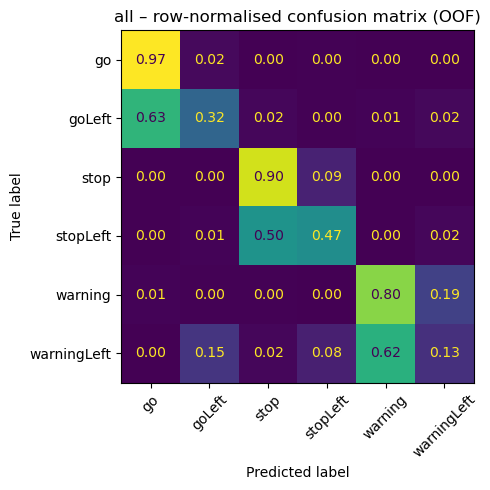

In [11]:
BEST = "all"
oof = oofs[BEST]
print(classification_report(y, oof, labels=CLASSES, zero_division=0, digits=3))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y, oof, labels=CLASSES, normalize="true"),
                       display_labels=CLASSES).plot(ax=ax, values_format=".2f", colorbar=False)
ax.set_title(f"{BEST} – row-normalised confusion matrix (OOF)")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

In [12]:
# Day vs night
res = {"all": error_decomposition(y, oof)}
for night in [False, True]:
    m = ann["isNight"].to_numpy() == night
    res["night" if night else "day"] = error_decomposition(y[m], oof[m])
pd.DataFrame(res).round(4)

,all,day,night
6-class error,0.1526,0.1854,0.0641
color error,0.0115,0.0137,0.0053
shape error,0.1412,0.1717,0.0588
3-class color acc.,0.9885,0.9863,0.9947
red -> green rate,0.0054,0.0050,0.0075


In [13]:
# Per-clip errors, split into colour and shape errors
tc = pd.Series(y).map(COLOR_OF).to_numpy()
pc = pd.Series(oof).map(COLOR_OF).to_numpy()
per_clip = pd.DataFrame({"clip": groups, "wrong": y != oof,
                         "color_err": tc != pc, "shape_err": (tc == pc) & (y != oof),
                         "red_as_green": (tc == "red") & (pc == "green")})
(per_clip.groupby("clip")
         .agg(n=("wrong", "size"), wrong=("wrong", "mean"), color_err=("color_err", "mean"),
              shape_err=("shape_err", "mean"), red_as_green=("red_as_green", "sum"))
         .round(3).sort_values("wrong", ascending=False))

,n,wrong,color_err,shape_err,red_as_green
clip,,,,,
dayTrain/dayClip9,390,0.444,0.056,0.387,5
dayTrain/dayClip3,230,0.335,0.000,0.335,0
dayTrain/dayClip2,437,0.330,0.000,0.330,0
dayTrain/dayClip6,227,0.322,0.009,0.313,0
dayTrain/dayClip11,255,0.314,0.020,0.294,5
dayTrain/dayClip5,1944,0.291,0.001,0.290,0
dayTrain/dayClip13,250,0.248,0.032,0.216,3
dayTrain/dayClip10,29,0.241,0.103,0.138,1
dayTrain/dayClip8,397,0.207,0.060,0.146,2


## 9. Look at errors

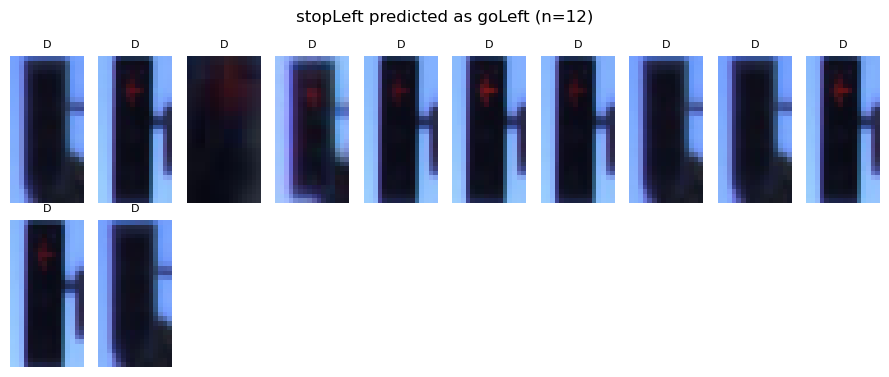

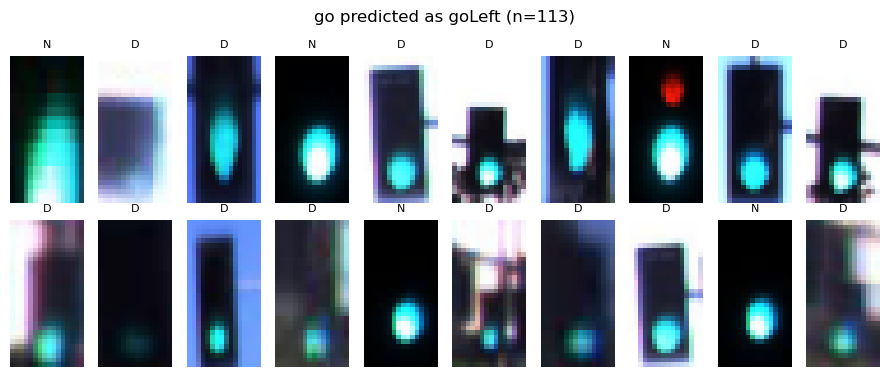

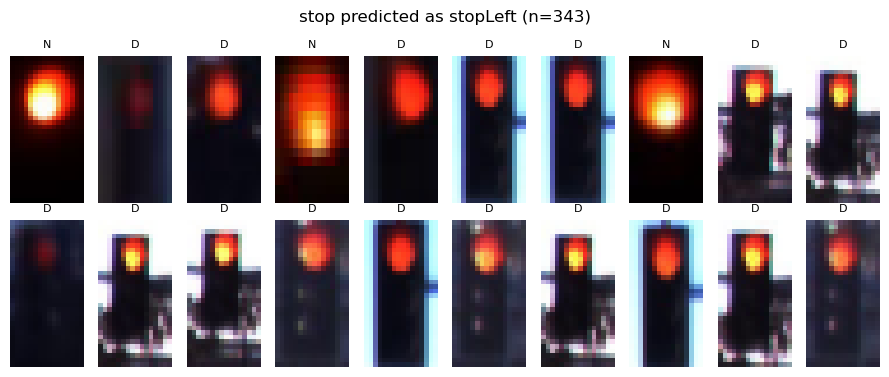

In [14]:
def show(mask, title, n=20, cols=10):
    """Show up to n cached patches selected by a boolean mask (D = day, N = night)."""
    idx = np.where(mask)[0]
    if len(idx) == 0:
        print(f"{title}: no samples"); return
    idx = np.random.default_rng(0).choice(idx, min(n, len(idx)), replace=False)
    rows = (len(idx) + cols - 1) // cols
    fig, ax = plt.subplots(rows, cols, figsize=(cols * 0.9, rows * 1.9), squeeze=False)
    for a in ax.flat:
        a.axis("off")
    for a, j in zip(ax.flat, idx):
        a.imshow(P[j]); a.set_title("N" if ann.at[j, "isNight"] else "D", fontsize=8)
    fig.suptitle(f"{title} (n={mask.sum()})"); plt.tight_layout(); plt.show()

show((y == "stopLeft") & (oof == "goLeft"), "stopLeft predicted as goLeft")
show((y == "go") & (oof == "goLeft"), "go predicted as goLeft")
show((y == "stop") & (oof == "stopLeft"), "stop predicted as stopLeft")

## 10. Export the data package for the teammate (run once folds are final)
- `splits/annotations_clean.csv` – one row per sample, with `fold`; small text file, **commit to git**.
- `cache/features_color_pos_red_hog.npz` – features in the same row order, with column names; share via cloud drive (not git).

In [15]:
feature_names = ([f"hue_{i}" for i in range(18)] + [f"sat_{i}" for i in range(8)] +
                 [f"val_{i}" for i in range(8)] + ["lit_frac"] +
                 ["pos_top", "pos_mid", "pos_bot", "pos_brightest_y"] +
                 ["red_frac", "red_max"] + [f"hog_{i}" for i in range(N_HOG)])
assert len(feature_names) == X.shape[1]

os.makedirs("splits", exist_ok=True)
ann_out = ann[["frame", "clip", "isNight", "tag", "x1", "y1", "x2", "y2", "w", "h", "fold"]].copy()
ann_out["color"] = ann_out["tag"].map(COLOR_OF)
ann_out.to_csv("splits/annotations_clean.csv", index=False)

np.savez_compressed(os.path.join(CACHE_DIR, "features_color_pos_red_hog.npz"),
                    X=X, feature_names=np.array(feature_names),
                    params=np.array([f"K_SUBSAMPLE={K_SUBSAMPLE}", f"MIN_H={MIN_H}", f"PATCH_WH={PATCH_WH}",
                                     f"HOG={HOG_ORIENT},{HOG_PPC},{HOG_CPB}"]))
print("Exported", ann_out.shape, X.shape)

Exported (10392, 12) (10392, 797)


In [16]:
print(pd.read_csv("splits/annotations_clean.csv")["fold"].value_counts().sort_index())

fold
0    1938
1    1475
2    2518
3    2234
4    2227
Name: count, dtype: int64
